# Laboratório: Análise de Dados com Pandas — Estudo de Caso da Tabela FIPE 🚗

**Disciplina:** Laboratório de Programação — Ciência da Computação (UFPI)  
**Prof.:** Armando Soares Sousa — Departamento de Computação

---

## 🎯 Objetivos da atividade

Ao final deste laboratório você será capaz de:

1. Explicar o que são **Series** e **DataFrames** no Pandas.
2. **Carregar** um conjunto de dados real (arquivo CSV) para dentro do Python.
3. **Explorar** os dados: tamanho, colunas, tipos, primeiras linhas, estatísticas.
4. **Selecionar** colunas e **filtrar** linhas a partir de condições.
5. **Agrupar** dados (`groupby`) para responder perguntas como "qual a marca mais cara?".
6. **Visualizar** resultados com gráficos simples (Matplotlib).
7. Desenvolver **senso crítico** sobre os dados: nem todo número significa o que parece!

## 🗺️ Roteiro sugerido (≈ 100 minutos)

| Parte | Conteúdo | Tempo |
|---|---|---|
| 0 | Preparação do ambiente | 5 min |
| 1 | Aquecimento: um DataFrame pequeno, feito à mão | 20 min |
| 2 | Carregando e conhecendo a Tabela FIPE | 15 min |
| 3 | Perguntas guiadas sobre os dados | 40 min |
| 4 | Exercícios para você resolver | 20 min |

## 🧭 Como usar este notebook

- Execute as células **na ordem**, de cima para baixo (atalho: `Shift + Enter`).
- **Leia o texto antes de executar** cada célula de código e tente **prever o resultado**.
- Os blocos marcados com **🤔 Pare e pense** são para discussão com a turma.
- Os blocos **✍️ Sua vez** têm células vazias para você escrever código.
- Errou? Faz parte! Leia a mensagem de erro com calma: ela costuma dizer exatamente o que aconteceu.

---
# Parte 0 — Preparação do ambiente

Antes de tudo, precisamos **importar** as bibliotecas. Importar é como "tirar a ferramenta da caixa" para poder usá-la.

| Biblioteca | Apelido usado | Para que serve |
|---|---|---|
| `pandas` | `pd` | manipular tabelas de dados |
| `matplotlib.pyplot` | `plt` | desenhar gráficos |

> 💡 Os apelidos `pd` e `plt` são uma **convenção** da comunidade Python. Você vai encontrá-los em praticamente todo material sobre o assunto.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Mostra a versão instalada (útil quando algo não funciona como esperado)
print("Versão do Pandas:", pd.__version__)

Versão do Pandas: 2.2.3


Vamos também configurar como os números decimais aparecem nas tabelas, para ficarem mais fáceis de ler
(com separador de milhar e 2 casas decimais):

In [23]:
pd.set_option("display.float_format", "{:,.2f}".format)

---
# Parte 1 — Aquecimento: um DataFrame pequeno

Antes de analisar meio milhão de linhas, vamos entender os conceitos com uma tabela de **4 carros** que conseguimos ver inteira na tela.

## 1.1 O que é um DataFrame?

Um **DataFrame** é uma **tabela**: tem **linhas** e **colunas**, como uma planilha do Excel.

- Cada **coluna** tem um **nome** (ex.: `carro`, `ano`) e guarda valores de um mesmo tipo.
- Cada **linha** tem um **índice** (por padrão: 0, 1, 2, ...) e representa um registro (aqui, um carro).

Uma forma simples de criar um DataFrame é a partir de um **dicionário** Python, em que:
- cada **chave** vira o nome de uma coluna;
- cada **lista** vira os valores daquela coluna.

In [24]:
dados_carros = {
    "carro": ["Corolla", "Ranger", "HB20", "ix35"],
    "ano":   [2012, 2015, 2018, 2020],
    "valor": [50000, 90000, 60000, 100000],
    "marca": ["Toyota", "Ford", "Hyundai", "Hyundai"],
}

df_carros = pd.DataFrame(dados_carros)
df_carros

,carro,ano,valor,marca
0,Corolla,2012,50000,Toyota
1,Ranger,2015,90000,Ford
2,HB20,2018,60000,Hyundai
3,ix35,2020,100000,Hyundai


Repare na coluna "sem nome" à esquerda (0, 1, 2, 3): é o **índice** das linhas.

O atributo `shape` informa o tamanho da tabela no formato **(linhas, colunas)**:

In [25]:
print("Formato (linhas, colunas):", df_carros.shape)
print(f"O DataFrame tem {df_carros.shape[0]} linhas e {df_carros.shape[1]} colunas.")

Formato (linhas, colunas): (4, 4)
O DataFrame tem 4 linhas e 4 colunas.


## 1.2 Selecionando colunas: Series × DataFrame

Para pegar **uma** coluna, usamos o nome dela entre colchetes `[ ]`.
O resultado é uma **Series**: uma estrutura com **uma única coluna** de valores + o índice.

In [26]:
coluna_carro = df_carros["carro"]
print(type(coluna_carro))
coluna_carro

<class 'pandas.core.series.Series'>


0    Corolla
1     Ranger
2       HB20
3       ix35
Name: carro, dtype: object

Podemos acessar um elemento da Series pelo seu **índice**:

In [27]:
df_carros["carro"][2]   # o carro da linha de índice 2

'HB20'

Para pegar **várias** colunas, passamos uma **lista** de nomes — por isso aparecem **colchetes duplos** `[[ ]]`.
O resultado agora é um **DataFrame** (uma tabela menor).

In [28]:
df_carro_valor = df_carros[["carro", "valor"]]
print(type(df_carro_valor))
df_carro_valor

<class 'pandas.core.frame.DataFrame'>


,carro,valor
0,Corolla,50000
1,Ranger,90000
2,HB20,60000
3,ix35,100000


> 🤔 **Pare e pense:** qual a diferença entre `df_carros["carro"]` e `df_carros[["carro"]]`? Execute os dois na célula abaixo e observe o tipo (`type`) e a forma como cada um é exibido.

## 1.3 Conhecendo os dados rapidamente

Estes são os comandos que você vai usar **sempre** que receber uma tabela nova:

| Comando | O que faz |
|---|---|
| `df.head(n)` | mostra as **n primeiras** linhas |
| `df.tail(n)` | mostra as **n últimas** linhas |
| `df.info()` | colunas, tipos de dados e valores não nulos |
| `df.describe()` | estatísticas das colunas numéricas |
| `df["col"].unique()` | valores **distintos** de uma coluna |
| `df["col"].nunique()` | **quantidade** de valores distintos |
| `df["col"].value_counts()` | quantas vezes **cada** valor aparece |

In [9]:
df_carros.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   carro   4 non-null      object
 1   ano     4 non-null      int64 
 2   valor   4 non-null      int64 
 3   marca   4 non-null      object
dtypes: int64(2), object(2)
memory usage: 260.0+ bytes


Na saída de `info()`:
- `int64` = números inteiros;
- `object` ou `str` = texto (o nome exato depende da versão do Pandas);
- `non-null` = quantos valores **não estão vazios** em cada coluna.

In [10]:
df_carros.describe()

,ano,valor
count,4.00,4.00
mean,"2,016.25","75,000.00"
std,3.50,"23,804.76"
min,"2,012.00","50,000.00"
25%,"2,014.25","57,500.00"
50%,"2,016.50","75,000.00"
75%,"2,018.50","92,500.00"
max,"2,020.00","100,000.00"


O `describe()` resume as colunas numéricas:

| Linha | Significado |
|---|---|
| `count` | quantidade de valores |
| `mean` | média |
| `std` | desvio padrão (o quanto os valores se espalham em torno da média) |
| `min` / `max` | menor e maior valor |
| `25%`, `50%`, `75%` | quartis — o `50%` é a **mediana** (o valor "do meio") |

In [31]:
print("Marcas distintas:", df_carros["marca"].unique())
print("Quantidade de marcas:", df_carros["marca"].nunique())
print()
print("Carros por marca:")
print(df_carros["marca"].value_counts())

Marcas distintas: ['Toyota' 'Ford' 'Hyundai']
Quantidade de marcas: 3

Carros por marca:
marca
Hyundai    2
Toyota     1
Ford       1
Name: count, dtype: int64


In [32]:
print("Valor médio:", df_carros["valor"].mean())
print("Maior valor:", df_carros["valor"].max())
print("Menor valor:", df_carros["valor"].min())

Valor médio: 75000.0
Maior valor: 100000
Menor valor: 50000


## 1.4 Filtrando linhas

Filtrar é **ficar só com as linhas que satisfazem uma condição**. Existem duas formas comuns.

### Forma 1: máscara booleana

Primeiro criamos uma **condição**. O resultado é uma Series de `True`/`False` — uma para cada linha:

In [33]:
mascara = df_carros["ano"] >= 2018
mascara

0    False
1    False
2     True
3     True
Name: ano, dtype: bool

Depois usamos essa "máscara" dentro dos colchetes: o Pandas devolve **apenas as linhas marcadas com `True`**.

In [34]:
df_carros[mascara]

,carro,ano,valor,marca
2,HB20,2018,60000,Hyundai
3,ix35,2020,100000,Hyundai


Para combinar condições usamos `&` (**E**), `|` (**OU**) e `~` (**NÃO**).
Cada condição precisa estar entre **parênteses**:

In [35]:
df_carros[(df_carros["marca"] == "Hyundai") & (df_carros["valor"] > 70000)]

,carro,ano,valor,marca
3,ix35,2020,100000,Hyundai


### Forma 2: o método `query`

O `query` permite escrever a condição como um **texto**, de forma mais parecida com a linguagem natural.
Aqui usamos `and`, `or` e `not` normalmente:

In [36]:
df_carros.query("ano >= 2018")

,carro,ano,valor,marca
2,HB20,2018,60000,Hyundai
3,ix35,2020,100000,Hyundai


In [37]:
df_carros.query("marca == 'Hyundai' and valor > 70000")

,carro,ano,valor,marca
3,ix35,2020,100000,Hyundai


> 💡 Repare nas **aspas**: o texto da consulta usa aspas duplas `"..."` e o valor textual `'Hyundai'` usa aspas simples. Se usar o mesmo tipo de aspas nos dois, o Python se confunde.

## 1.5 Ordenando

`sort_values` ordena as linhas por uma coluna. Use `ascending=False` para ordem **decrescente**.

In [38]:
df_carros.sort_values(by="valor", ascending=False)

,carro,ano,valor,marca
3,ix35,2020,100000,Hyundai
1,Ranger,2015,90000,Ford
2,HB20,2018,60000,Hyundai
0,Corolla,2012,50000,Toyota


### ✍️ Sua vez (aquecimento)

1. Mostre apenas os carros da marca **Toyota** ou **Ford**.
2. Mostre o carro **mais barato** (dica: ordene e use `head(1)`).

In [19]:
# 1.

In [20]:
# 2.

---
# Parte 2 — Carregando e conhecendo a Tabela FIPE

## 2.1 O que é a Tabela FIPE?

A **FIPE** (Fundação Instituto de Pesquisas Econômicas — https://www.fipe.org.br/) publica todo mês o **preço médio de venda** de veículos no Brasil.
Ela é usada como referência para compra e venda de carros usados, seguros, financiamentos e cálculo de impostos.

Vamos trabalhar com um **fragmento histórico** da tabela: preços de automóveis entre **2001 e 2022**.

## 2.2 Lendo os dados

O arquivo está compactado (`.zip`) e contém um CSV. 

> ⏳ O arquivo tem cerca de 30 MB; a leitura pode levar alguns segundos.

> 💡 **Alternativa (Google Colab / Linux):** baixar e descompactar o arquivo com comandos do terminal e depois ler o CSV localmente:
> ```
> !wget https://github.com/armandossrecife/teste/raw/refs/heads/main/lp/archive.zip
> !unzip -o archive.zip
> df_fipe = pd.read_csv("tabela-fipe-historico-precos.csv")
> ```

## 2.3 Primeiro contato com os dados

In [39]:
!wget https://github.com/armandossrecife/teste/raw/refs/heads/main/lp/archive.zip

--2026-10-22 12:13:17--  https://github.com/armandossrecife/teste/raw/refs/heads/main/lp/archive.zip
Resolvendo github.com (github.com)... 4.228.31.150
Conectando-se a github.com (github.com)|4.228.31.150|:443... conectado.
A requisição HTTP foi enviada, aguardando resposta... 302 Found
Localização: https://raw.githubusercontent.com/armandossrecife/teste/refs/heads/main/lp/archive.zip [redirecionando]
--2026-10-22 12:13:18--  https://raw.githubusercontent.com/armandossrecife/teste/refs/heads/main/lp/archive.zip
Resolvendo raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8001::154, 2606:50c0:8000::154, 2606:50c0:8003::154, ...
Conectando-se a raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8001::154|:443... conectado.
A requisição HTTP foi enviada, aguardando resposta... 200 OK
Tamanho: 5887805 (5,6M) [application/zip]
Salvando em: “archive.zip”

archive.zip         100%[===================>]   5,61M  18,2MB/s    em 0,3s    

2026-10-22 12:13:19 (18,2 M

In [40]:
!unzip -o archive.zip

Archive:  archive.zip
  inflating: tabela-fipe-historico-precos.csv  


In [41]:
df_fipe = pd.read_csv("tabela-fipe-historico-precos.csv")

In [42]:
print(f"A tabela tem {df_fipe.shape[0]:,} linhas e {df_fipe.shape[1]} colunas.")

A tabela tem 466,020 linhas e 8 colunas.


In [44]:
df_fipe.head()

,Unnamed: 0,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor
0,0,038003-2,Acura,Integra GS 1.8,1992,11,2016,"13,041.00"
1,1,038001-6,Acura,NSX 3.0,1995,3,2013,"52,339.00"
2,2,038003-2,Acura,Integra GS 1.8,1992,3,2018,"12,423.00"
3,3,038002-4,Acura,Legend 3.2/3.5,1998,5,2016,"31,067.00"
4,4,038002-4,Acura,Legend 3.2/3.5,1998,2,2019,"26,381.00"


Existe uma coluna chamada `Unnamed: 0`. Ela é só uma **numeração de linhas** que sobrou quando o arquivo foi salvo — não traz informação útil.
Vamos removê-la com `drop`:

In [45]:
df_fipe = df_fipe.drop(columns=["Unnamed: 0"])
df_fipe.head()

,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor
0,038003-2,Acura,Integra GS 1.8,1992,11,2016,"13,041.00"
1,038001-6,Acura,NSX 3.0,1995,3,2013,"52,339.00"
2,038003-2,Acura,Integra GS 1.8,1992,3,2018,"12,423.00"
3,038002-4,Acura,Legend 3.2/3.5,1998,5,2016,"31,067.00"
4,038002-4,Acura,Legend 3.2/3.5,1998,2,2019,"26,381.00"


> 💡 Escrevemos `df_fipe = df_fipe.drop(...)` porque o `drop` **não altera** a tabela original: ele **devolve uma nova** tabela. Por isso guardamos o resultado de volta na variável.

## 2.4 Dicionário de dados

Antes de analisar, precisamos entender **o que cada coluna significa**:

| Coluna | Significado | Exemplo |
|---|---|---|
| `codigoFipe` | código que identifica a versão do veículo na FIPE | `015096-7` |
| `marca` | fabricante | `Toyota` |
| `modelo` | nome do modelo/versão | `Corolla XEi 2.0 Flex 16V Aut.` |
| `anoModelo` | ano do modelo do veículo | `2014` |
| `mesReferencia` | **mês** em que o preço foi pesquisado | `8` (agosto) |
| `anoReferencia` | **ano** em que o preço foi pesquisado | `2022` |
| `valor` | preço médio em reais (R$) | `85000.0` |

⚠️ **Atenção a um ponto essencial:** cada linha **não** é um carro diferente. Cada linha é **o preço de uma versão de carro, de um ano-modelo, em um mês específico**.
O mesmo carro aparece **várias vezes**, uma para cada mês em que o preço foi pesquisado. Isso vai fazer diferença nas nossas análises!

In [46]:
df_fipe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466020 entries, 0 to 466019
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   codigoFipe     466020 non-null  object 
 1   marca          466020 non-null  object 
 2   modelo         466020 non-null  object 
 3   anoModelo      466020 non-null  int64  
 4   mesReferencia  466020 non-null  int64  
 5   anoReferencia  466020 non-null  int64  
 6   valor          466020 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 24.9+ MB


O `info()` mostra que:
- há **466 mil** linhas;
- nenhuma coluna tem valores vazios (o número de *non-null* é igual ao total de linhas);
- `anoModelo`, `mesReferencia` e `anoReferencia` são inteiros; `valor` é decimal (`float64`); as demais são texto.

Também podemos contar os valores vazios diretamente:

In [47]:
df_fipe.isna().sum()

codigoFipe       0
marca            0
modelo           0
anoModelo        0
mesReferencia    0
anoReferencia    0
valor            0
dtype: int64

In [48]:
df_fipe.describe()

,anoModelo,mesReferencia,anoReferencia,valor
count,"466,020.00","466,020.00","466,020.00","466,020.00"
mean,"2,008.97",6.45,"2,015.18","115,745.60"
std,10.00,3.42,5.68,"325,073.71"
min,"1,985.00",1.00,"2,001.00","1,871.00"
25%,"2,000.00",4.00,"2,011.00","19,388.00"
50%,"2,009.00",6.00,"2,017.00","39,416.50"
75%,"2,020.00",9.00,"2,020.00","84,794.50"
max,"2,023.00",12.00,"2,022.00","8,407,082.00"


> 🤔 **Pare e pense:** olhe a coluna `valor` no `describe()`.
> - A **média** (`mean`) é bem maior que a **mediana** (`50%`). Por que isso acontece?
> - O **valor máximo** passa de R$ 8 milhões! Que tipo de carro poderia ser esse?
>
> (Vamos responder essas perguntas mais adiante.)

## 2.5 Preparando os dados: criando uma coluna de data

O mês e o ano de referência estão em **duas colunas separadas**. Para fazer gráficos ao longo do tempo, é mais prático ter **uma única coluna de data**.

Vamos montar um texto no formato `"ano-mês-01"` e convertê-lo para data com `pd.to_datetime`:

In [49]:
df_fipe["dataReferencia"] = pd.to_datetime(
    df_fipe["anoReferencia"].astype(str) + "-" + df_fipe["mesReferencia"].astype(str) + "-01"
)

df_fipe[["mesReferencia", "anoReferencia", "dataReferencia"]].head()

,mesReferencia,anoReferencia,dataReferencia
0,11,2016,2016-11-01
1,3,2013,2013-03-01
2,3,2018,2018-03-01
3,5,2016,2016-05-01
4,2,2019,2019-02-01


> 💡 `astype(str)` converte números em texto, para podermos "colar" os pedaços com `+`.

Vamos também criar uma pequena **função** para exibir valores em reais no formato brasileiro (R$ 1.234,56):

In [50]:
def formatar_reais(valor):
    texto = f"{valor:,.2f}"            # formato americano: 1,234.56
    texto = texto.replace(",", "X")     # troca temporária
    texto = texto.replace(".", ",")     # ponto vira vírgula
    texto = texto.replace("X", ".")     # vírgula vira ponto
    return "R$ " + texto

print(formatar_reais(1234.5))
print(formatar_reais(8407082))

R$ 1.234,50
R$ 8.407.082,00


---
# Parte 3 — Perguntas guiadas

Análise de dados começa com **perguntas**. Para cada pergunta abaixo, seguimos o mesmo ciclo:

> **Pergunta → Ideia (qual comando usar?) → Código → Interpretação do resultado**

## Pergunta 1 — Quantas e quais marcas existem na tabela?

**Ideia:** `nunique()` conta as marcas distintas e `unique()` lista quais são.

In [51]:
qtd_marcas = df_fipe["marca"].nunique()
print(f"Existem {qtd_marcas} marcas na tabela.")

Existem 84 marcas na tabela.


In [52]:
lista_marcas = sorted(df_fipe["marca"].unique())
print(lista_marcas)

['ASTON MARTIN', 'Acura', 'Agrale', 'Alfa Romeo', 'Asia Motors', 'Audi', 'BMW', 'BRM', 'BYD', 'Baby', 'Bugre', 'CHANA', 'CHANGAN', 'Cadillac', 'Caoa Chery', 'Chrysler', 'Citroën', 'Cross Lander', 'Daewoo', 'Daihatsu', 'Dodge', 'EFFA', 'Engesa', 'Envemo', 'Ferrari', 'Fiat', 'Fibravan', 'Ford', 'Fyber', 'GEELY', 'GM - Chevrolet', 'GREAT WALL', 'Gurgel', 'HAFEI', 'HITECH ELECTRIC', 'Honda', 'Hyundai', 'Isuzu', 'JAC', 'JINBEI', 'Jaguar', 'Jeep', 'Kia Motors', 'LAMBORGHINI', 'LIFAN', 'LOBINI', 'Lada', 'Land Rover', 'Lexus', 'Lotus', 'MG', 'MINI', 'Mahindra', 'Maserati', 'Matra', 'Mazda', 'Mclaren', 'Mercedes-Benz', 'Mercury', 'Mitsubishi', 'Nissan', 'Peugeot', 'Plymouth', 'Pontiac', 'Porsche', 'RAM', 'RELY', 'Renault', 'Rolls-Royce', 'Rover', 'SHINERAY', 'SSANGYONG', 'Saab', 'Saturn', 'Seat', 'Subaru', 'Suzuki', 'Toyota', 'Troller', 'VW - VolksWagen', 'Volvo', 'Wake', 'Walk', 'smart']


E quais marcas têm **mais registros**? `value_counts()` conta e já ordena do maior para o menor:

In [53]:
registros_por_marca = df_fipe["marca"].value_counts()
registros_por_marca.head(10)

marca
Renault            44464
Peugeot            41828
Audi               33837
VW - VolksWagen    29838
Ford               26128
Volvo              22296
Mitsubishi         21912
Toyota             20615
Nissan             19009
Honda              18131
Name: count, dtype: int64

Um gráfico de barras deixa a comparação mais visual. Toda Series do Pandas tem o método `.plot()`:

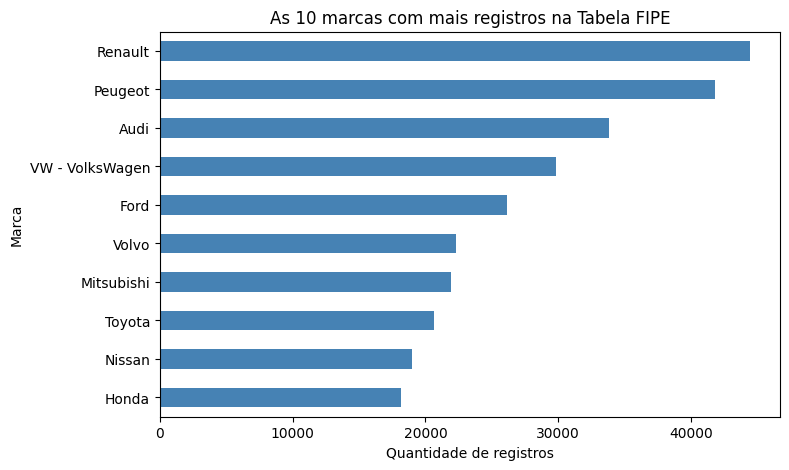

In [54]:
top10 = registros_por_marca.head(10)

top10.sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("As 10 marcas com mais registros na Tabela FIPE")
plt.xlabel("Quantidade de registros")
plt.ylabel("Marca")
plt.show()

> 🤔 **Pare e pense:** ter **mais registros** significa que a marca **vende mais carros** no Brasil?
> Lembre-se: cada registro é *um preço, de uma versão, em um mês*. Uma marca com muitas versões diferentes (ou pesquisada por muitos anos) terá muitos registros, mesmo vendendo pouco.

## Pergunta 2 — Quantos modelos existem? Quais marcas têm mais modelos?

**Ideia:** `nunique()` na coluna `modelo`. Para contar **por marca**, usamos `groupby`.

In [55]:
print(f"Existem {df_fipe['modelo'].nunique():,} modelos/versões diferentes.")

Existem 5,366 modelos/versões diferentes.


### Entendendo o `groupby`

O `groupby` funciona em três passos (*dividir → aplicar → combinar*):

1. **Dividir** a tabela em grupos (ex.: um grupo para cada marca);
2. **Aplicar** um cálculo em cada grupo (ex.: contar modelos distintos);
3. **Combinar** os resultados em uma nova tabela.

```
df.groupby("coluna_do_grupo")["coluna_calculada"].função()
```

In [56]:
modelos_por_marca = df_fipe.groupby("marca")["modelo"].nunique()
modelos_por_marca.sort_values(ascending=False).head(10)

marca
VW - VolksWagen    501
Fiat               490
Mercedes-Benz      359
Ford               349
Renault            304
Audi               288
BMW                253
Peugeot            247
Citroën            201
Hyundai            194
Name: modelo, dtype: int64

## Pergunta 3 — Qual o período coberto pelos dados?

**Ideia:** `min()` e `max()` na coluna de data.

In [57]:
inicio = df_fipe["dataReferencia"].min()
fim = df_fipe["dataReferencia"].max()
print("Primeira referência:", inicio.strftime("%m/%Y"))
print("Última referência:  ", fim.strftime("%m/%Y"))

Primeira referência: 01/2001
Última referência:   08/2022


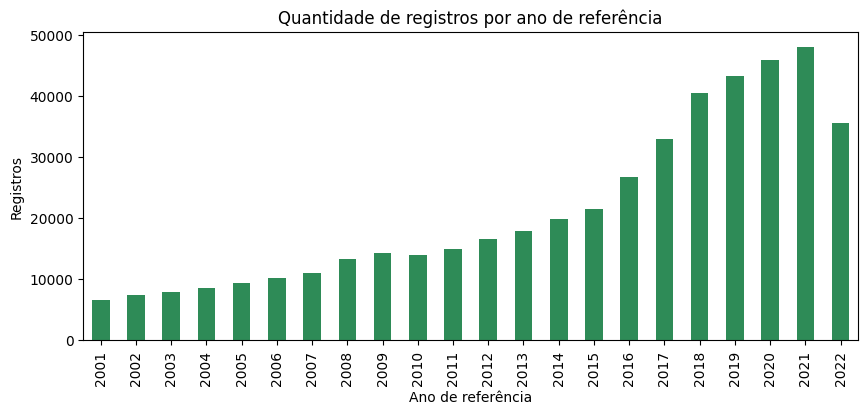

In [58]:
registros_por_ano = df_fipe["anoReferencia"].value_counts().sort_index()

registros_por_ano.plot(kind="bar", figsize=(10, 4), color="seagreen")
plt.title("Quantidade de registros por ano de referência")
plt.xlabel("Ano de referência")
plt.ylabel("Registros")
plt.show()

> 🤔 **Pare e pense:**
> - Por que a quantidade de registros cresce ao longo dos anos?
> - Por que 2022 tem menos registros que 2021? (Dica: veja qual é o último mês disponível.)

## Pergunta 4 — Quais são os carros com o ano-modelo mais antigo e o mais novo?

**Ideia:** descobrir o menor e o maior `anoModelo` e depois **filtrar** as linhas com esses anos.

In [59]:
menor_ano = df_fipe["anoModelo"].min()
maior_ano = df_fipe["anoModelo"].max()
print(f"Ano-modelo mais antigo: {menor_ano}")
print(f"Ano-modelo mais novo:   {maior_ano}")

Ano-modelo mais antigo: 1985
Ano-modelo mais novo:   2023


In [60]:
mais_antigos = df_fipe.query("anoModelo == @menor_ano")
print("Modelos mais antigos:", mais_antigos["modelo"].unique())
mais_antigos.head()

Modelos mais antigos: ['Oggi']


,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor,dataReferencia
92001,001105-3,Fiat,Oggi,1985,5,2022,"3,289.00",2022-05-01
92182,001105-3,Fiat,Oggi,1985,7,2022,"3,305.00",2022-07-01
92270,001105-3,Fiat,Oggi,1985,8,2022,"3,285.00",2022-08-01
93115,001105-3,Fiat,Oggi,1985,6,2022,"3,315.00",2022-06-01


> 💡 Dentro do `query`, o símbolo `@` permite usar uma **variável Python** (aqui, `menor_ano`).

In [61]:
mais_novos = df_fipe.query("anoModelo == @maior_ano")
mais_novos

,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor,dataReferencia
43159,039001-1,BRM,Buggy/M-8/M-8 Long 1.6,2023,8,2022,"83,377.00",2022-08-01


> 🤔 **Pare e pense:** um carro **ano-modelo 2023** com preço pesquisado em **agosto de 2022**. Isso faz sentido?
> Sim! No Brasil, montadoras lançam o "modelo do ano seguinte" ainda no segundo semestre.

## Pergunta 5 — Investigando os dados: o que significa `anoModelo == 2022`? 🕵️

Vamos contar quantos registros existem para cada ano-modelo recente:

In [62]:
df_fipe["anoModelo"].value_counts().sort_index().tail(8)

anoModelo
2016     11943
2017      9317
2018      8209
2019      5922
2020      2782
2021       818
2022    114871
2023         1
Name: count, dtype: int64

Algo estranho: há **muito mais** registros com ano-modelo 2022 do que com 2021, 2020, 2019...
Vamos ver **em quais anos de referência** aparecem carros com ano-modelo 2022:

In [63]:
df_fipe.query("anoModelo == 2022")["anoReferencia"].value_counts().sort_index()

anoReferencia
2001    3018
2002    3700
2003    3123
2004    2868
2005    2994
2006    3201
2007    3758
2008    4347
2009    4607
2010    3989
2011    4214
2012    4976
2013    5614
2014    5967
2015    6081
2016    7233
2017    8298
2018    8423
2019    8321
2020    7529
2021    7752
2022    4858
Name: count, dtype: int64

🚨 Existem preços de carros **ano-modelo 2022** pesquisados em **2001**! Um carro 2022 não existia em 2001.

**Explicação mais provável:** na FIPE, o preço de um carro **0 km** (novo) é identificado por um código especial de ano (`32000`).
Ao montar este conjunto de dados, esses registros de **carros novos** parecem ter sido gravados como `anoModelo = 2022`.
Ou seja: em `anoModelo == 2022` estão misturados os **preços de carros 0 km ao longo de 22 anos**.

> 🎓 **Lição importante:** antes de tirar conclusões, **questione os dados**! Valores "estranhos" muitas vezes revelam como os dados foram coletados ou processados. Esse cuidado separa uma análise correta de uma análise enganosa.

Vamos ver um exemplo concreto — um Corolla "2022" pesquisado em 2005:

In [64]:
exemplo = df_fipe.query("anoModelo == 2022 and anoReferencia == 2005")
exemplo[exemplo["modelo"].str.contains("Corolla")].head()

,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor,dataReferencia
392791,002084-2,Toyota,Corolla Fielder SW 1.8/1.8 XEi Flex Aut.,2022,4,2005,"66,381.00",2005-04-01
392805,002084-2,Toyota,Corolla Fielder SW 1.8/1.8 XEi Flex Aut.,2022,11,2005,"69,554.00",2005-11-01
392944,002080-0,Toyota,Corolla XLi 1.6 16V 110cv Aut.,2022,1,2005,"50,663.00",2005-01-01
393512,002028-1,Toyota,Corolla XEi 1.8/1.8 Flex 16V Mec.,2022,5,2005,"58,870.00",2005-05-01
393570,002080-0,Toyota,Corolla XLi 1.6 16V 110cv Aut.,2022,10,2005,"55,566.00",2005-10-01


## Pergunta 6 — Qual o preço médio dos carros Toyota ano-modelo 2022?

### Primeira tentativa (ingênua)

In [65]:
toyota_2022 = df_fipe.query("marca == 'Toyota' and anoModelo == 2022")
media_ingenua = toyota_2022["valor"].mean()

print(f"Registros encontrados: {len(toyota_2022):,}")
print("Preço médio:", formatar_reais(media_ingenua))

Registros encontrados: 7,523
Preço médio: R$ 92.886,92


> 🤔 **Pare e pense:** depois do que vimos na Pergunta 5, essa média é confiável?
> Ela mistura preços de carros novos de **2001 até 2022** — e os preços mudaram muito nesse período (inflação, novos modelos...).

### Segunda tentativa (correta): usando apenas a referência mais recente

Para comparar preços de forma justa, devemos usar **o mesmo mês de referência** para todos os carros.
Vamos usar o mês mais recente da tabela:

In [66]:
data_mais_recente = df_fipe["dataReferencia"].max()
df_recente = df_fipe[df_fipe["dataReferencia"] == data_mais_recente]

print("Mês de referência:", data_mais_recente.strftime("%m/%Y"))
print(f"Registros nesse mês: {len(df_recente):,}")

Mês de referência: 08/2022
Registros nesse mês: 5,146


In [67]:
toyota_2022_recente = df_recente.query("marca == 'Toyota' and anoModelo == 2022")
media_correta = toyota_2022_recente["valor"].mean()

print(f"Registros encontrados: {len(toyota_2022_recente)}")
print("Preço médio (referência mais recente):", formatar_reais(media_correta))

Registros encontrados: 31
Preço médio (referência mais recente): R$ 154.297,87


In [68]:
toyota_2022_recente[["modelo", "valor"]].sort_values("valor")

,modelo,valor
397065,YARIS XL Live 1.3 Flex 16V 5p Aut.,"88,709.00"
394409,YARIS XL Plus Con. 1.5 Flex 16V 5p Aut.,"93,032.00"
404047,YARIS XL 1.5 Flex 16V 5p Aut.,"93,381.00"
410975,YARIS XL Live Sedan 1.5 Flex 16V 4p Aut.,"94,089.00"
400946,YARIS XL Plus Con. Sed. 1.5 Flex 16V Aut,"96,271.00"
405709,YARIS XL Sedan 1.5 Flex 16V 4p Aut.,"97,356.00"
397293,YARIS XS Connect 1.5 Flex 16V 5p Aut.,"98,067.00"
407335,YARIS XS Connect Sedan 1.5 Flex 16V Aut.,"101,093.00"
398873,YARIS XS 1.5 Flex 16V 5p Aut.,"102,320.00"
406766,YARIS XLS Connect 1.5 Flex 16V 5p Aut.,"103,814.00"


Compare as duas médias. A diferença mostra como uma pergunta mal formulada leva a uma resposta errada!

## Pergunta 7 — Como o preço do Corolla 0 km evoluiu ao longo dos anos?

Agora vamos **aproveitar** a descoberta da Pergunta 5: se `anoModelo == 2022` guarda preços de carros novos ao longo do tempo, podemos ver como o preço de um carro **zero** mudou entre 2001 e 2022.

### Passo 1 — Filtrar os Corollas

Para buscar um **pedaço de texto** dentro de uma coluna usamos `.str.contains()`.
Vamos excluir o **Corolla Cross** (que é um SUV, outro tipo de carro) usando o `~` (**NÃO**):

In [69]:
toyota_0km = df_fipe.query("marca == 'Toyota' and anoModelo == 2022")

eh_corolla = toyota_0km["modelo"].str.contains("Corolla")
eh_cross = toyota_0km["modelo"].str.contains("Cross")

corolla_0km = toyota_0km[eh_corolla & ~eh_cross]

print(f"Registros de Corolla 0 km: {len(corolla_0km)}")
corolla_0km.head()

Registros de Corolla 0 km: 1924


,codigoFipe,marca,modelo,anoModelo,mesReferencia,anoReferencia,valor,dataReferencia
392382,002060-5,Toyota,Corolla SE-G 1.8/1.8 Flex 16V Aut.,2022,5,2002,"49,944.00",2002-05-01
392391,002027-3,Toyota,Corolla XLi 1.8/1.8 Flex 16V Mec.,2022,8,2002,"32,536.00",2002-08-01
392392,002084-2,Toyota,Corolla Fielder SW 1.8/1.8 XEi Flex Aut.,2022,8,2004,"64,655.00",2004-08-01
392402,002060-5,Toyota,Corolla SE-G 1.8/1.8 Flex 16V Aut.,2022,2,2010,"82,291.00",2010-02-01
392417,002109-1,Toyota,Corolla GLi 1.8 Flex 16V Aut.,2022,7,2010,"68,000.00",2010-07-01


### Passo 2 — Calcular o preço médio por ano de referência (`groupby`)

In [70]:
preco_corolla_por_ano = corolla_0km.groupby("anoReferencia")["valor"].mean()
preco_corolla_por_ano

anoReferencia
2001    38,122.40
2002    40,297.17
2003    47,087.74
2004    54,615.45
2005    61,254.32
2006    63,329.92
2007    66,209.60
2008    67,753.26
2009    66,181.67
2010    70,137.63
2011    69,619.94
2012    68,547.44
2013    68,547.86
2014    71,411.42
2015    76,014.11
2016    83,114.79
2017    91,294.27
2018    98,275.57
2019   101,880.71
2020   123,359.05
2021   149,130.89
2022   169,030.48
Name: valor, dtype: float64

### Passo 3 — Visualizar

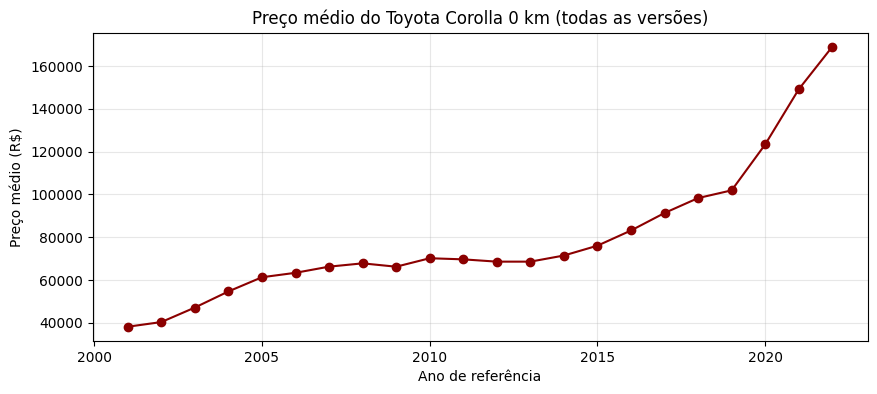

In [71]:
preco_corolla_por_ano.plot(kind="line", marker="o", figsize=(10, 4), color="darkred")
plt.title("Preço médio do Toyota Corolla 0 km (todas as versões)")
plt.xlabel("Ano de referência")
plt.ylabel("Preço médio (R$)")
plt.grid(True, alpha=0.3)
plt.show()

In [72]:
primeiro = preco_corolla_por_ano.iloc[0]
ultimo = preco_corolla_por_ano.iloc[-1]
aumento = (ultimo / primeiro - 1) * 100

print("Preço médio em 2001:", formatar_reais(primeiro))
print("Preço médio em 2022:", formatar_reais(ultimo))
print(f"Aumento: {aumento:.0f}%")

Preço médio em 2001: R$ 38.122,40
Preço médio em 2022: R$ 169.030,48
Aumento: 343%


> 💡 `iloc[0]` pega o **primeiro** elemento pela **posição**; `iloc[-1]` pega o **último**.

> 🤔 **Pare e pense:** o aumento se deve apenas à inflação? Que outros fatores podem explicar? (Dica: versões mais caras, como as híbridas, só surgiram nos últimos anos — e a média mistura todas as versões.)

Podemos também ver a **distribuição** dos preços do Corolla 0 km na referência mais recente com um **histograma**:

                                  modelo      valor
           Corolla GLi 2.0 16V Flex Aut. 145,080.00
           Corolla XEi 2.0 Flex 16V Aut. 151,959.00
      Corolla GR-Sport 2.0 Flex 16V Aut. 174,393.00
Corolla ALTIS/A.Premiu. 2.0 Flex 16V Aut 175,714.00
       Corolla Altis Hybrid 1.8 16V Aut. 178,908.00
      Corolla Altis Prem. Hybrid 1.8 Aut 186,893.00


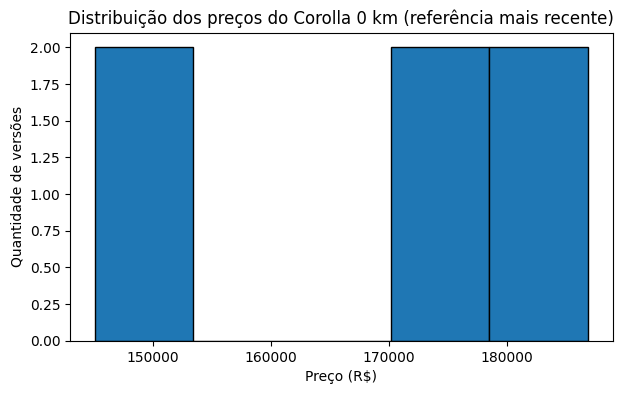

In [73]:
corolla_recente = corolla_0km[corolla_0km["dataReferencia"] == data_mais_recente]
print(corolla_recente[["modelo", "valor"]].sort_values("valor").to_string(index=False))

corolla_recente["valor"].plot(kind="hist", bins=5, figsize=(7, 4), edgecolor="black")
plt.title("Distribuição dos preços do Corolla 0 km (referência mais recente)")
plt.xlabel("Preço (R$)")
plt.ylabel("Quantidade de versões")
plt.show()

## Pergunta 8 — Quanto um carro usado desvaloriza com o tempo?

Agora vamos acompanhar **um mesmo carro** ao longo do tempo: o **Hyundai HB20X Premium 1.6 Mec., ano-modelo 2014**.
Para identificar exatamente essa versão usamos o `codigoFipe` **e** o `anoModelo`.

In [74]:
hb20x_2014 = df_fipe.query("codigoFipe == '015096-7' and anoModelo == 2014")
hb20x_2014 = hb20x_2014.sort_values("dataReferencia")

print("Modelo:", hb20x_2014["modelo"].iloc[0])
print(f"Preços registrados: {len(hb20x_2014)} meses")
hb20x_2014[["dataReferencia", "valor"]].head()

Modelo: HB20X Premium 1.6 Flex 16V Mec.
Preços registrados: 84 meses


,dataReferencia,valor
151531,2015-09-01,"43,689.00"
153706,2015-10-01,"43,855.00"
145113,2015-11-01,"44,429.00"
155443,2015-12-01,"45,414.00"
151363,2016-01-01,"46,415.00"


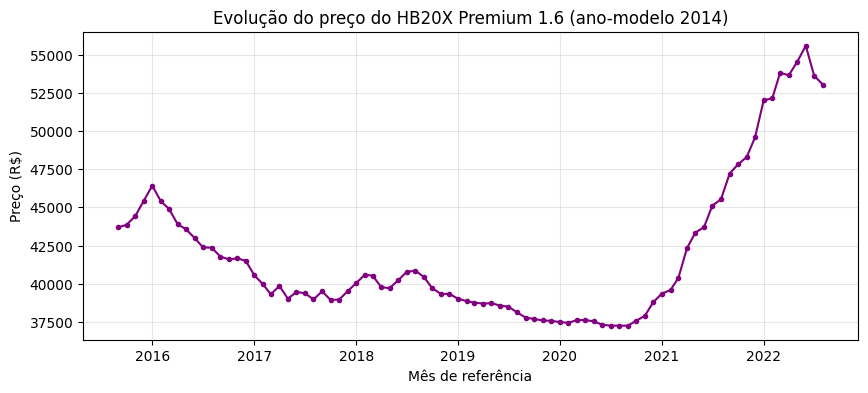

In [75]:
plt.figure(figsize=(10, 4))
plt.plot(hb20x_2014["dataReferencia"], hb20x_2014["valor"], marker=".", color="purple")
plt.title("Evolução do preço do HB20X Premium 1.6 (ano-modelo 2014)")
plt.xlabel("Mês de referência")
plt.ylabel("Preço (R$)")
plt.grid(True, alpha=0.3)
plt.show()

> 🤔 **Pare e pense:** o gráfico não é sempre decrescente. Em alguns períodos o preço do carro **usado** subiu. O que pode ter acontecido? (Pense, por exemplo, em 2020–2021: pandemia, falta de peças e de carros novos nas concessionárias...)

## Pergunta 9 — Quais marcas têm os carros mais caros?

**Ideia:** usar `df_recente` (só o mês mais recente, para comparar de forma justa) e agrupar por marca calculando **várias** estatísticas de uma vez com `agg`.

In [76]:
resumo_marcas = df_recente.groupby("marca")["valor"].agg(["count", "mean", "median"])
resumo_marcas.columns = ["registros", "media", "mediana"]
resumo_marcas.sort_values("mediana", ascending=False).head(10)

,registros,media,mediana
marca,,,
Rolls-Royce,8,"5,019,110.00","5,342,276.00"
LAMBORGHINI,20,"3,364,215.20","3,374,128.50"
Mclaren,10,"3,453,283.50","2,944,688.50"
Ferrari,49,"2,235,640.71","1,682,165.00"
ASTON MARTIN,11,"936,247.27","774,455.00"
Porsche,142,"756,619.67","687,986.00"
RAM,1,"483,113.00","483,113.00"
BYD,4,"392,756.25","385,522.50"
Land Rover,105,"345,283.55","332,775.00"


### Média × Mediana

- A **média** soma todos os valores e divide pela quantidade. Ela é **puxada** por valores muito altos (ou muito baixos).
- A **mediana** é o valor **do meio** quando ordenamos os dados. Ela é **resistente** a valores extremos.

Exemplo: os salários `[2, 2, 3, 3, 100]` (em mil reais) têm média **22** e mediana **3**. Qual descreve melhor o "salário típico"?

Por isso, em preços de carros (onde existem alguns superesportivos caríssimos) a **mediana** costuma representar melhor o "carro típico" de uma marca.

Vamos olhar apenas marcas com uma quantidade razoável de registros (pelo menos 100) para evitar conclusões baseadas em poucos carros:

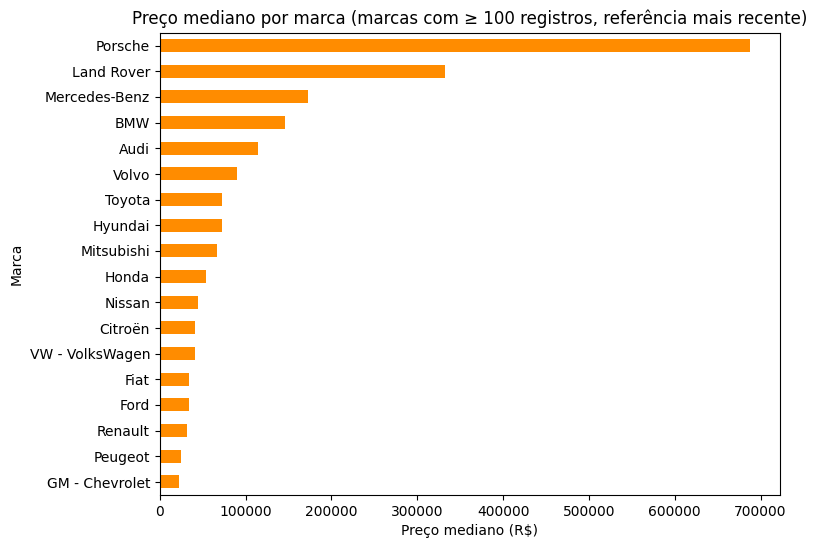

In [77]:
marcas_populares = resumo_marcas[resumo_marcas["registros"] >= 100]
marcas_populares = marcas_populares.sort_values("mediana")

marcas_populares["mediana"].plot(kind="barh", figsize=(8, 6), color="darkorange")
plt.title("Preço mediano por marca (marcas com ≥ 100 registros, referência mais recente)")
plt.xlabel("Preço mediano (R$)")
plt.ylabel("Marca")
plt.show()

## Pergunta 10 — Qual é o carro mais caro da tabela?

**Ideia:** `nlargest(n, coluna)` devolve as `n` linhas com os maiores valores de uma coluna.

In [78]:
df_fipe.nlargest(5, "valor")[["marca", "modelo", "anoModelo", "dataReferencia", "valor"]]

,marca,modelo,anoModelo,dataReferencia,valor
85963,Ferrari,SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido),2022,2022-05-01,"8,407,082.00"
91044,Ferrari,SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido),2022,2022-07-01,"8,407,082.00"
88128,Ferrari,SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido),2022,2022-06-01,"8,400,000.00"
88736,Ferrari,SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido),2022,2022-04-01,"8,400,000.00"
88761,Ferrari,SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido),2022,2022-08-01,"8,400,000.00"


In [79]:
mais_caro = df_fipe.loc[df_fipe["valor"].idxmax()]
print(f"O carro mais caro é o {mais_caro['marca']} {mais_caro['modelo']}, "
      f"custando {formatar_reais(mais_caro['valor'])} em {mais_caro['dataReferencia']:%m/%Y}.")

O carro mais caro é o Ferrari SF 90 SPIDER 4.0 V8 Bi-Turbo (Híbrido), custando R$ 8.407.082,00 em 05/2022.


> 💡 `idxmax()` devolve o **índice** da linha com o maior valor; `loc[índice]` busca essa linha.

Agora conseguimos responder a pergunta da Parte 2: a **média** de `valor` é bem maior que a **mediana** porque poucos carros extremamente caros (como este Ferrari) "puxam" a média para cima.

---
# Parte 4 — ✍️ Exercícios

Resolva os exercícios nas células abaixo. Use as perguntas guiadas como referência — quase todos os comandos necessários já apareceram!

> ⚠️ Lembre-se da lição da Pergunta 5: quando for **comparar preços**, prefira usar `df_recente` (mesmo mês de referência para todos).

**Exercício 1.** Quantos modelos/versões diferentes da marca **Fiat** existem na tabela?

In [ ]:
# Exercício 1

**Exercício 2.** Usando `df_recente`, qual o preço **médio** e o preço **mediano** dos carros da marca **Honda**? Exiba os valores com a função `formatar_reais`.

In [ ]:
# Exercício 2

**Exercício 3.** Usando `df_recente`, liste os **5 carros mais baratos** (mostre as colunas `marca`, `modelo`, `anoModelo` e `valor`).

*Dica:* existe `nsmallest`, o "irmão" do `nlargest`.

In [ ]:
# Exercício 3

**Exercício 4.** Usando `df_recente`, quantos carros custam **entre R$ 50.000 e R$ 100.000**?

In [ ]:
# Exercício 4

**Exercício 5.** Usando `df_recente`, encontre todas as versões que contêm a palavra **"Híbrido"** ou **"Hybrid"** no nome do modelo. Quantas são? Qual a marca com mais versões híbridas?

*Dica:* `str.contains("Híbrido|Hybrid")` — a barra vertical `|` significa **OU** dentro do texto de busca.

In [ ]:
# Exercício 5

**Exercício 6.** Escolha um carro de seu interesse (por exemplo, um **Gol** ou um **HB20**) e repita a análise da **Pergunta 8**: faça o gráfico da evolução do preço de uma versão específica (`codigoFipe` + `anoModelo`).

*Dica:* para descobrir os códigos disponíveis, filtre pelo nome do modelo e use
`groupby(["codigoFipe", "modelo", "anoModelo"]).size().sort_values(ascending=False).head()`.

In [ ]:
# Exercício 6

**Exercício 7.** Usando `df_recente`, calcule o **preço mediano por ano-modelo** (`groupby("anoModelo")`) e faça um gráfico de linha. O que o gráfico mostra sobre a relação entre a idade do carro e o seu preço? O ponto de 2022 se comporta como esperado?

In [ ]:
# Exercício 7

**Exercício 8 (desafio).** Para a versão do HB20X da Pergunta 8, calcule a **desvalorização percentual** entre o **primeiro** e o **último** preço registrados.

*Dica:* reveja como calculamos o aumento do Corolla na Pergunta 7.

In [ ]:
# Exercício 8

**Exercício 9 (discussão).** Escreva em uma célula de texto (Markdown) **uma pergunta nova** que você gostaria de responder com estes dados, e tente respondê-la com código.

In [ ]:
# Exercício 9

---
# 📌 Resumo dos comandos usados

| Objetivo | Comando |
|---|---|
| Ler um CSV | `pd.read_csv("arquivo.csv")` |
| Tamanho da tabela | `df.shape` |
| Primeiras / últimas linhas | `df.head()` / `df.tail()` |
| Tipos e valores não nulos | `df.info()` |
| Estatísticas | `df.describe()` |
| Contar valores vazios | `df.isna().sum()` |
| Remover coluna | `df.drop(columns=["col"])` |
| Uma coluna (Series) | `df["col"]` |
| Várias colunas (DataFrame) | `df[["col1", "col2"]]` |
| Valores distintos | `df["col"].unique()` / `df["col"].nunique()` |
| Frequência de cada valor | `df["col"].value_counts()` |
| Filtrar com máscara | `df[df["col"] > 10]` |
| Filtrar com texto | `df.query("col > 10 and outra == 'x'")` |
| Buscar texto | `df["col"].str.contains("palavra")` |
| Ordenar | `df.sort_values("col", ascending=False)` |
| Maiores / menores | `df.nlargest(5, "col")` / `df.nsmallest(5, "col")` |
| Agrupar | `df.groupby("grupo")["col"].mean()` |
| Várias estatísticas | `df.groupby("grupo")["col"].agg(["mean", "median"])` |
| Converter para data | `pd.to_datetime(...)` |
| Gráfico rápido | `serie.plot(kind="bar" / "barh" / "line" / "hist")` |

## 🎓 O que aprendemos sobre análise de dados

1. **Entenda o que cada linha representa** antes de calcular qualquer coisa.
2. **Questione valores estranhos** — eles podem revelar problemas (ou oportunidades) nos dados.
3. **Compare coisas comparáveis** — por exemplo, preços do mesmo mês de referência.
4. **Média nem sempre é a melhor medida** — com valores extremos, a mediana costuma ser mais representativa.
5. **Visualize** — um gráfico frequentemente revela o que uma tabela esconde.

## 📚 Referências

- Documentação oficial do Pandas: https://pandas.pydata.org/docs/
- Guia "10 minutes to pandas": https://pandas.pydata.org/docs/user_guide/10min.html
- Documentação do Matplotlib: https://matplotlib.org/stable/
- Fundação Instituto de Pesquisas Econômicas (FIPE): https://www.fipe.org.br/